# 01 - Train water / tree: how much of our own (Mae Suai) data do we need?
- **Train on:** all OpenEarthMap (OEM) images + **0% / 25% / 50% / 75% / 100%** of our Mae Suai images (these are the **seen** images).
- **Test on:** the Mae Suai images **not** used for training (the **unseen** share): 0% -> 100% unseen, 25% -> 75% unseen, 50% -> 50% unseen. At 100% nothing is unseen, so the score is measured on the training images (fit only, not generalization).
- Image and mask are matched by **same file name** (`1.tif` image <-> `1.tif` mask in `own_paired`; notebook 01 section 2 makes this folder).
- All settings (classes, model, training) come from `configs/water_tree.yaml`. To switch model, change `model.active` there.
- The code lives in `src/` (data, models, training, plots). This notebook only sets the options, runs the training and draws the results.

## 1. Setup

In [11]:
print("Helki")

Helki


In [12]:
%load_ext autoreload
%autoreload 2

import os, sys, json
import torch
import pandas as pd
REPO_DIR = r"C:\land_cover_senior2026"
os.chdir(REPO_DIR); sys.path.insert(0, REPO_DIR)

from src.train import load_config
from src.data.paths import resolve_paths
from src.data.pairing import pair_folder, shuffle_pairs, split_for
from src.data.seg_dataset import get_oem_ids
from src.experiments.fraction import run_fraction
from src.visualization.plots import (print_table, plot_miou, plot_confusions, plot_iou_heatmap,
                                     plot_prediction_by_filename, print_metrics_table, setup_viewer)


cfg = load_config("configs/water_tree.yaml")

# ---- CHOOSE THE MODEL HERE (no need to edit the yaml) ----
MODEL_CHOICE = "fpn_swin_b"       # unet_r34 | fpn_r34 | fpn_swin_b
assert MODEL_CHOICE in cfg["models"], f"pick one of {list(cfg['models'])}"
cfg["model"]["active"] = MODEL_CHOICE

# ---- the option you can change ----
FRACTIONS = [0.0, 0.25, 0.5, 0.75, 1.0]         # share of ALL Mae Suai images used (seen) in training; the rest is unseen test

P = resolve_paths(cfg)
CLASSES    = cfg["classes"]
MODEL_NAME = cfg["model"]["active"]
SEED       = cfg["train"]["seed"]
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "| model:", MODEL_NAME, "|", cfg["models"][MODEL_NAME], "| classes:", CLASSES)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Device: cuda | model: fpn_swin_b | {'decoder': 'fpn', 'encoder': 'tu-swinv2_base_window8_256', 'encoder_weights': 'imagenet'} | classes: ['other', 'tree', 'water']


## 2. Pair images with masks and make the fixed split
Images and masks are matched by the same file name. All Mae Suai images are shuffled once (seed in the yaml) and saved to `results/own_split.json`.
For a fraction `f`, the first `f` of the shuffled list is **seen** (training) and the rest is **unseen** (test). So the 25% images are always inside the 50% images, and those inside the 100% images.

In [13]:
from src.data.pairing import pair_images_and_labels

own_pairs = pair_folder(P["own_images"], P["own_masks"])
oem_pairs = pair_images_and_labels(P["oem_root"])  # Updated to scan all OEM regions automatically
print("Mae Suai pairs:", len(own_pairs), "| OEM pairs:", len(oem_pairs))
assert len(own_pairs) > 0, "No Mae Suai pairs - run notebook 01 section 2 first"

own_shuffled = shuffle_pairs(own_pairs, SEED)
json.dump({"order": [a.stem for a, _ in own_shuffled]}, open(P["results_dir"] / "own_split.json", "w"), indent=2)

total = len(own_shuffled)
for f in FRACTIONS:
    seen, unseen = split_for(own_shuffled, f)
    note = "  (no unseen images left -> tested on seen images)" if f >= 1.0 else ""
    print(f"  {int(f*100):3d}% -> seen (train) {round(f*total):3d} | unseen (test) {total - round(f*total):3d}{note}")

OWN_IDS = cfg["mask_ids"]["own"]
OEM_IDS, oem_seen = get_oem_ids(cfg, oem_pairs)
print("own mask ids:", OWN_IDS)
print("oem mask ids:", OEM_IDS, "| values seen in OEM labels:", sorted(oem_seen) if oem_seen else "n/a")

Successfully paired 2687 images with their matching labels across all OEM regions.
Mae Suai pairs: 31 | OEM pairs: 2687
    0% -> seen (train)   0 | unseen (test)  31
   25% -> seen (train)   8 | unseen (test)  23
   50% -> seen (train)  16 | unseen (test)  15
   75% -> seen (train)  23 | unseen (test)   8
  100% -> seen (train)  31 | unseen (test)   0  (no unseen images left -> tested on seen images)
own mask ids: {'tree': [5], 'water': [6], 'ignore': [0, 9]}
oem mask ids: {'tree': [5], 'water': [6], 'ignore': [0]} | values seen in OEM labels: [0, 1, 2, 3, 4, 5, 6, 7, 8]


## 3. Train
This trains one model per option, so it takes a while. Change `FRACTIONS` in section 1 to run fewer.
Same recipe as `train.py` (cross-entropy + Dice, Adam, mixed precision). The score reported is from the **last epoch**, so we do not pick the best epoch using the test images.

In [14]:
results = []
for f in FRACTIONS:
    results.append(run_fraction(f, cfg, device, oem_pairs, own_shuffled, OEM_IDS, OWN_IDS, P["weights_dir"]))
    json.dump(results, open(P["results_dir"] / f"own_fraction_{MODEL_NAME}_results.json", "w"), indent=2)


=== fpn_swin_b (Encoder: tu-swinv2_base_window8_256 | Decoder: fpn) | 0% ===
Images trained on: 2687 OEM + 0 Mae Suai = 2687 unique images
Samples per epoch (Mae Suai x5 repeat): 2687
Test on 31 unseen Mae Suai images
epoch  1 | train_loss 0.834 | test mIoU 0.343
epoch  2 | train_loss 0.638 | test mIoU 0.260
epoch  3 | train_loss 0.576 | test mIoU 0.157
epoch  4 | train_loss 0.531 | test mIoU 0.088
epoch  5 | train_loss 0.530 | test mIoU 0.300
epoch  6 | train_loss 0.524 | test mIoU 0.297
epoch  7 | train_loss 0.501 | test mIoU 0.169
epoch  8 | train_loss 0.498 | test mIoU 0.419
epoch  9 | train_loss 0.485 | test mIoU 0.069
epoch 10 | train_loss 0.483 | test mIoU 0.179
epoch 11 | train_loss 0.487 | test mIoU 0.282
epoch 12 | train_loss 0.463 | test mIoU 0.036
epoch 13 | train_loss 0.481 | test mIoU 0.227
epoch 14 | train_loss 0.457 | test mIoU 0.085
epoch 15 | train_loss 0.447 | test mIoU 0.074
epoch 16 | train_loss 0.471 | test mIoU 0.283
epoch 17 | train_loss 0.467 | test mIoU 0.196

## 4. Results

In [15]:
# Convert results to a DataFrame to inspect the new columns
df_results = pd.DataFrame(results)
# Display model, encoder, decoder, time, and mIoU side-by-side
# Replace "mIoU" with the exact key name from your printout (e.g., "test_miou")
# Display model, encoder, decoder, time, and miou side-by-side
display(df_results[["model", "encoder", "decoder", "fraction", "train_time_min", "miou"]])

,model,encoder,decoder,fraction,train_time_min,miou
0,fpn_swin_b,tu-swinv2_base_window8_256,fpn,0.00,46.86,0.418503
1,fpn_swin_b,tu-swinv2_base_window8_256,fpn,0.25,31.65,0.553474
2,fpn_swin_b,tu-swinv2_base_window8_256,fpn,0.50,57.92,0.576559
3,fpn_swin_b,tu-swinv2_base_window8_256,fpn,0.75,73.01,0.625638
4,fpn_swin_b,tu-swinv2_base_window8_256,fpn,1.00,12.35,0.811337


Mae Suai in training   test imgs   mIoU   other    tree   water
  0% (0 imgs)                 31  0.419   0.204   0.821   0.231
 25% (8 imgs)                 23  0.553   0.011   0.904   0.347
 50% (16 imgs)                15  0.577   0.020   0.890   0.610
 75% (23 imgs)                 8  0.626   0.134   0.959   0.784
100% (31 imgs)                31  0.811   0.766   0.970   0.698


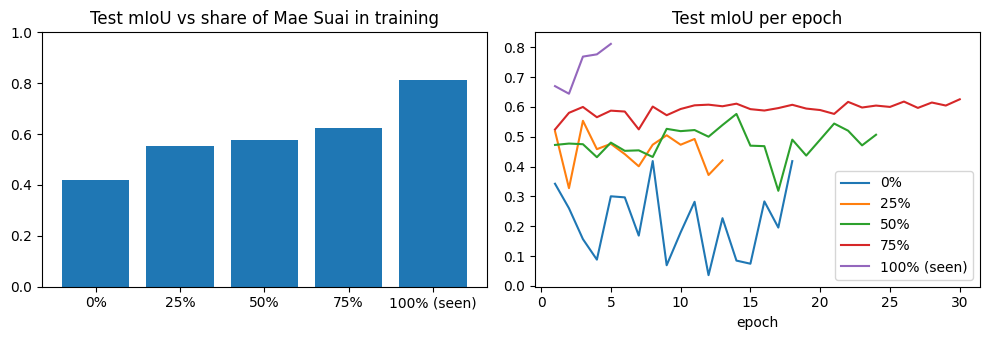

In [16]:
print_table(results, CLASSES)
plot_miou(results, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_miou.png")

## 5. Heatmaps
- **Confusion matrices** (one per option): each row is the true class, each column is what the model predicted. Numbers are the % of that true class, so the diagonal is correct and every off-diagonal cell is a specific mistake (e.g. true *tree* predicted as *other*).
- **IoU + mIoU heatmap**: one row per option, one column per class and the overall mIoU, for a side-by-side comparison.

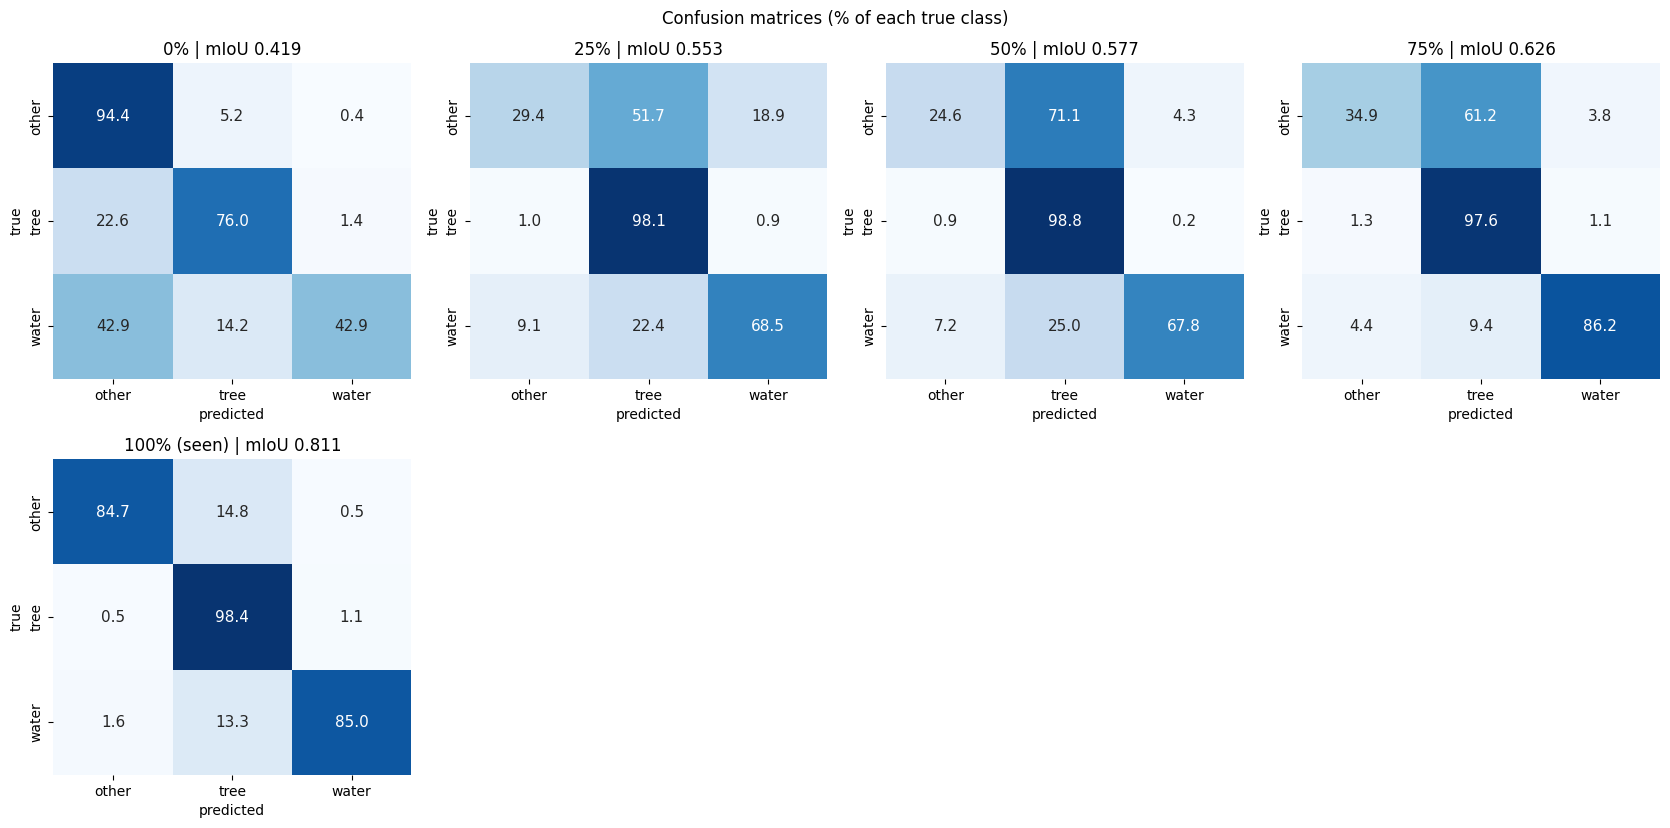

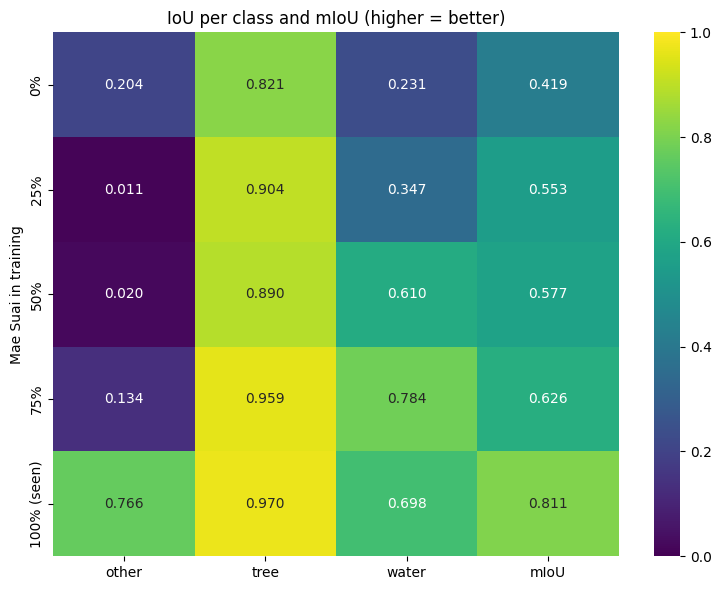

In [17]:
plot_confusions(results, CLASSES, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_confusion.png")
plot_iou_heatmap(results, CLASSES, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_iou_heatmap.png")

In [18]:
from src.visualization.plots import print_metrics_table

df = print_metrics_table(results, CLASSES,
                         save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_metrics.csv")

Mae Suai in training     class  precision  recall    F1   IoU  pixels accuracy
                  0%     other      0.171   0.944 0.290 0.169   58216         
                          tree      0.987   0.760 0.859 0.752 1075112         
                         water      0.601   0.429 0.501 0.334   54486         
                     macro avg      0.586   0.711 0.550 0.419 1187814    0.754
                 25%     other      0.576   0.294 0.389 0.242   58074         
                          tree      0.953   0.981 0.967 0.936  832060         
                         water      0.621   0.685 0.651 0.483   44391         
                     macro avg      0.717   0.653 0.669 0.553  934525    0.924
                 50%     other      0.668   0.246 0.360 0.219   58074         
                          tree      0.909   0.988 0.947 0.900  504658         
                         water      0.860   0.678 0.758 0.611   34148         
                     macro avg      0.812   0.638 0.

test images (8, from the 25% never used by models trained on <= 75%):
  [0] 54.tif  [1] 85.tif  [2] 57.tif  [3] 58.tif  [4] 80.tif  [5] 100.tif  [6] 53.tif  [7] 75.tif
models loaded: ['0%', '25%', '50%', '75%', '100%']
Showing: 85.tif  (dataset index 1)
Model input tensor: shape (3, 256, 256) | min -2.0262 | max 1.7574 | mean -1.3814


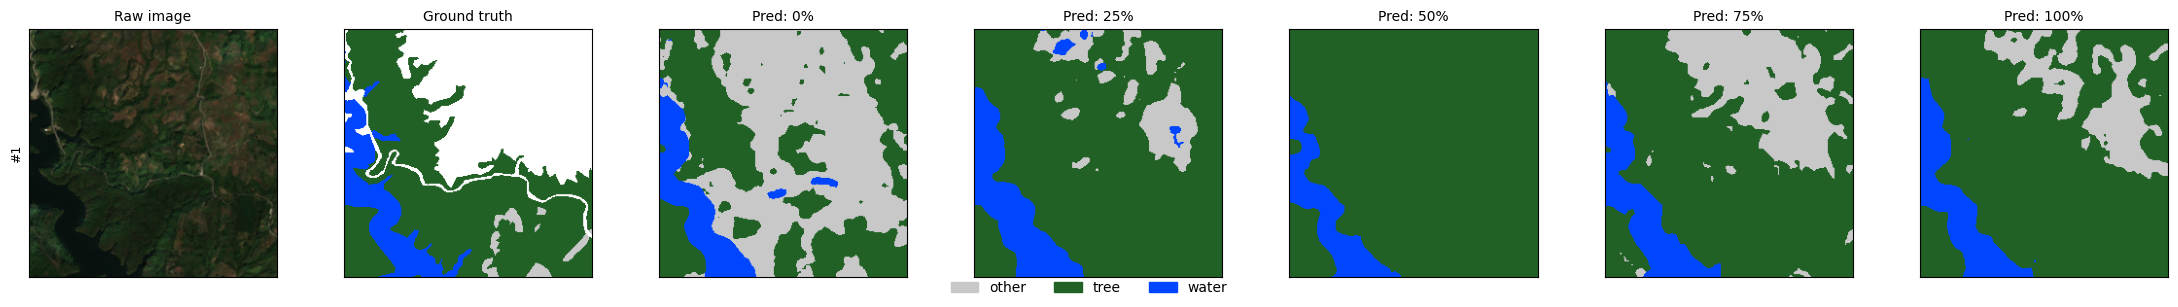

1

In [19]:
from src.visualization.plots import setup_viewer
show = setup_viewer(cfg, own_shuffled, OWN_IDS, P, device)
show("85.tif")

## Notes
- Each option has a **different test set** (0% tests on all images, 25% on 75%, 50% on 50%), so the scores are not measured on identical images. Small differences can be noise.
- The 100% option has no unseen images, so its score only shows how well the model fits its training data. Do not read it as generalization.
- The split order is listed in `results/own_split.json`. Weights and results files include the model name, so different models do not overwrite each other.
- Before committing to GitHub: *Kernel > Restart & Clear Output*.